In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hcipy import * 
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [2]:
## part 1: finding the response
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47 

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.3,speckle_window=60)

In [7]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')



In [8]:
for img in step:
    img -= np.median(img)

In [9]:
def dxdy(s):
    #this is the version of the dx dy function that assumes the center of the PSF is NOT well known
    ga = ADC.grating_angle

    sep = ADC.grating_freq * 2 * ADC.normalized_wavelength 
    d1 = sep * np.sin(np.radians(s[2]-ga))*np.sin(np.radians(ga-s[0])) / np.sin(np.radians((ga-s[0]) + (s[2]-ga)))
    d2 = -sep * np.sin(np.radians(s[1]+ga))*np.sin(np.radians(ga + s[3])) / np.sin(np.radians((s[1]+ga) + (ga + s[3])))

    #apply rotation matrix in the opposite direction of the grating angle
    dx = np.cos(np.radians(-ga)) * d1 - np.sin(np.radians(-ga)) * d2
    dy = np.sin(np.radians(-ga)) * d1 + np.cos(np.radians(-ga)) * d2

    return dx, dy

In [8]:
img = step[2]
hp = ADC.hpf(img,20)
img = ADC.crop_image(hp,extent=512,mask_diam=20)
#img = ADC.crop_image(img,extent=512,mask_diam=20)

s = ADC.all_speckle_angles(img)
dx, dy = dxdy(s)

imshow_field(img)
plt.title('filtered')
plt.colorbar()
plt.scatter(dx,dy,color='orange',label='est radiation center')
plt.legend()

print(f'speckle angles {s}')
print(f'dy: {dy}')
print(f'dx: {dx}')
print(f'est magnitude: {np.sqrt(dx**2 + dy**2)}')
print(f'est dir: {np.degrees(np.atan2(dy,dx))}')


ValueError: operands could not be broadcast together with shapes (262144,) (66049,) 

In [10]:
#and this is the version where we assume the center IS well known
est_x, est_y = ADC.speckles_dxdy(img,plotted=True,printed=False,filtered=True)
sq = np.sqrt(est_x**2+est_y**2)
ang = np.degrees(np.arctan2(est_y,est_x))
print(f'est dispersion {sq} pixels')
print(f'est disp axis {ang}°')

AttributeError: 'adcFitter2' object has no attribute 'speckles_dxdy'

Between those two images, it's really easy to see that the red dot is not in the right spot on the second image (it's way too far up). This leads to over-estimation of the amount of dispersion in the image. The first method identifies a radiation center that makes sense, and its calculated dispersion doesn't depend on the approximation used to find the psf center.

The first method is giving a funny number for the orientation, and I think it's because of the way I'm calculating the arctangent. I was doing arctan(x,y) instead of arctan(y,x) in the other script, because it was the only way to get the angle i was seeing visually to match the one I was calculating. However, I think the real reason for this discrepancy was that I forgot that plt.imshow shows the origin in the top left, not the bottom left. 

In [107]:
#filter all the image cubes from each step
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 
speckle_list = [] #speckle angle list at each step
dx_list = []
dy_list = []

for i, field in enumerate(step):
    img = ADC.hpf(field,20)
    img = ADC.crop_image(img,mask_diam=40,extent=512)
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    #imshow_field(img)
    a = ADC.all_speckle_angles(img,speckle_filter=False)
    speckle_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])

    # plt.figure()
    # est_x, est_y = ADC.speckles_dxdy(img,plotted=False,printed=False)
    # plt.show()
    
    dx, dy = dxdy(a)
    dx_list.append(dx)
    dy_list.append(dy)

dx_list = np.array(dx_list)
dy_list = np.array(dy_list)
diffs13_list = np.array(diffs13_list)
diffs24_list = np.array(diffs24_list)

sqs = np.sqrt(dx_list**2 + dy_list**2)
angs = np.atan2(dy_list,dx_list)

fitting error. could not fit speckle 0
fitting error. could not fit speckle 1


Slope of Speckles 1&3 Response: -3.2354888483142323
Offset of Speckles 1&3 Response: -6.7883795723561215
Slope of Speckles 2&4 Response: 4.882428672018188
Offset of Speckles 2&4 Response: 3.0235315792031847


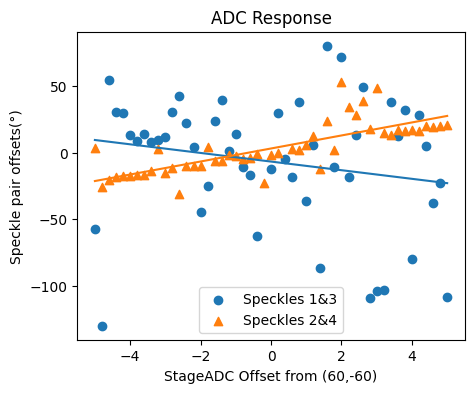

In [108]:
#plot the linear response
angle_offsets = np.linspace(-5,5,51) 

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(diffs13_list)
idxs24 = np.isfinite(diffs24_list)

h = [diffs13_list, diffs24_list]

avgs = [diffs13_list[idxs13], diffs24_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    plt.scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    plt.plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

#plt.scatter(0,0,color='Red')

plt.title('ADC Response')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Speckle pair offsets(°)')
plt.legend()
plt.show()

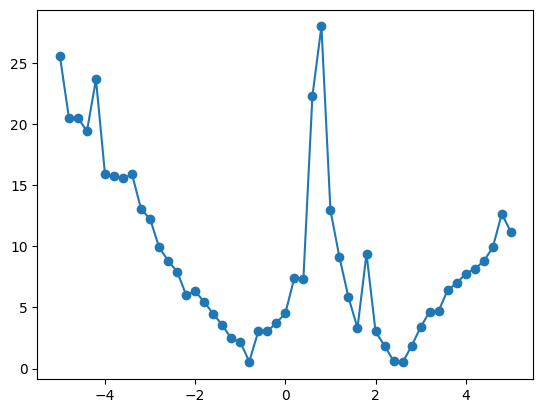

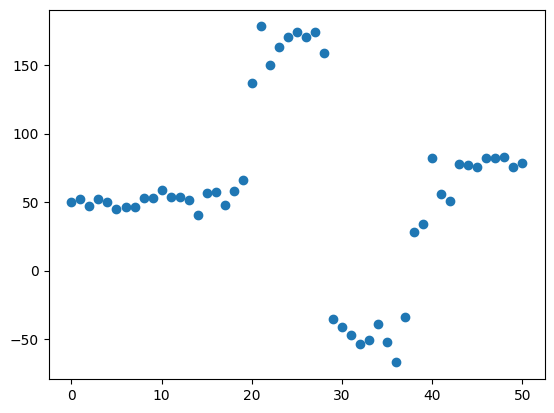

In [63]:
plt.plot(offsets[0],sqs,'-o')
plt.figure()
plt.plot(np.degrees(angs),'o')

oh yeah. i remember now. this never worked because it diverges when it's close to zero.

Let's try the method i used in projections.ipynb, which just averages the position of the four speckles to find the center.


In [65]:
def est_center(img,extent=40):

    cois = np.zeros((4,2))

    for i in range(4):
        speckle_number = i

        speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
        speckle_center = speckle_coords[speckle_number]
        rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

        speckle_img = rect * img

        #find the center of intensity of the speckle area and window the ORIGINAL image around that center
        center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
        window_size=ADC.speckle_window
        new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

        coi = np.array([sum(new_img*new_img.grid.x)/sum(new_img),sum(new_img*new_img.grid.y)/sum(new_img)])

        cois[i,:] = center_of_intensity + coi

    overall_coi = np.mean(cois,axis=0)
    return overall_coi


In [75]:
#filter all the image cubes from each step
dx_list = []
dy_list = []
sq_list = []
ang_list = []

for i, field in enumerate(step):
    img = ADC.hpf(field,30)
    img = ADC.crop_image(img,mask_diam=40,extent=512)
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    #imshow_field(img)
    center = est_center(img)
    
    dx, dy = ADC.speckles_dxdy(img,filtered=False)
    dx -= center[0]
    dy -= center[1]
    sq = np.sqrt(dx**2 + dy**2)
    ang = np.atan2(dy,dx)

    dx_list.append(dx)
    dy_list.append(dy)
    sq_list.append(sq)
    ang_list.append(ang)

dx_list = np.array(dx_list)
dy_list = np.array(dy_list)
sq_list = np.array(sq_list)
ang_list = np.degrees(np.array(ang_list))

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:126: RuntimeWarning: invalid value encountered in divide
  zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)


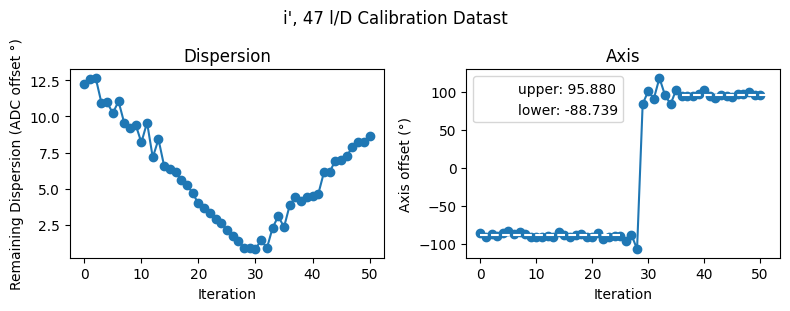

In [81]:
upper_axis_avg = np.mean(ang_list[36:])
lower_axis_avg = np.mean(ang_list[:25])

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(sq_list,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_list,'o-')
ax[1].hlines(upper_axis_avg,36,len(ang_list),color='white',linestyles='dashed',label=f'upper: {upper_axis_avg:.3f}')
ax[1].hlines(lower_axis_avg,0,25,color='white',linestyles='dashed',label=f'lower: {lower_axis_avg:.3f}')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].legend()
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D Calibration Datast')
fig.tight_layout()
plt.show()


In [100]:
#and how does it fare on an onsky dataset?
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')
for img in step:
    img -= np.median(img)

In [ ]:
#filter all the image cubes from each step
dx_list = []
dy_list = []
sq_list = []
ang_list = []

ADC.hp_sigma = 8
ADC.lp_sigma = 4

for i, field in enumerate(step):
    img = ADC.hpf(field,30)
    img = ADC.crop_image(img,mask_diam=40,extent=512)
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    #imshow_field(img)
    center = est_center(img)
    
    dx, dy = ADC.speckles_dxdy(img,filtered=True)
    dx -= center[0]
    dy -= center[1]
    sq = np.sqrt(dx**2 + dy**2)
    ang = np.atan2(dy,dx)

    dx_list.append(dx)
    dy_list.append(dy)
    sq_list.append(sq)
    ang_list.append(ang)

dx_list = np.array(dx_list)
dy_list = np.array(dy_list)
sq_list = np.array(sq_list)
ang_list = np.degrees(np.array(ang_list))

[0.08463821 0.72694239]
[0.07644911 0.47605318]
[0.12460047 0.63371494]
[0.08577447 0.3840101 ]
[0.08755262 0.47656509]
[0.10877788 0.62378776]
[0.08039643 0.84133362]
[-0.00289812  0.57597276]
[-0.19193247  0.6737419 ]
[0.04964838 0.63712626]
[-0.03508365  0.59565058]
[0.00163109 0.49113143]
[0.126019   0.51177589]


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


[0.04699002 0.56569357]
[-0.13594383  0.63700588]
[-0.26376764  0.6899225 ]
[0.1119688  0.66734072]
[0.17291377 0.73595633]
[0.11019987 0.48129856]
[0.07400878 0.68656795]
[-0.21262632  0.6236706 ]
[-0.09260301  0.92944172]
[-0.03315812  0.60770598]
[-0.08797681  0.69089546]
[0.01203781 0.51157638]
[-0.1364798   0.71728446]
[0.15725814 0.73919562]
[-0.12649842  0.69286904]
[0.02672593 0.88506932]
[0.06559398 0.6812832 ]
[-0.32293649  0.87667777]
[-0.06178409  1.02650699]
[0.0583293  0.85946841]
[0.11722127 0.81926076]
[0.11039544 0.98868386]
[0.127601   0.94266173]
[0.11369746 0.97080291]
[0.17221881 0.67671777]
[0.29781659 0.62765815]
[0.24265162 0.56252382]
[0.31059227 0.8511585 ]
[0.27144931 0.81049233]


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:126: RuntimeWarning: invalid value encountered in divide
  zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)


[-0.56976557  1.0881656 ]
[-0.17815907  1.15490506]
[0.1849786  0.78299077]
[-0.22522649  0.81904019]
[-0.279179    0.69672253]
[-0.33262169  1.08768472]
[-0.62145209  1.0999505 ]
[-0.18558604  0.95139751]
[-0.22809699  1.16825888]


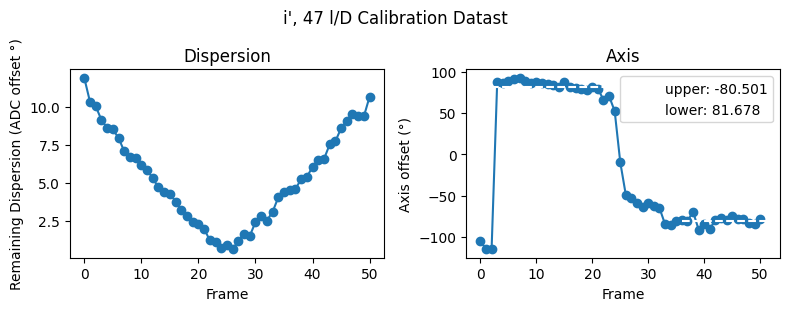

In [134]:
upper_axis_avg = np.mean(ang_list[36:])
lower_axis_avg = np.mean(ang_list[4:25])

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(sq_list,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Frame')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_list,'o-')
ax[1].hlines(upper_axis_avg,36,len(ang_list),color='white',linestyles='dashed',label=f'upper: {upper_axis_avg:.3f}')
ax[1].hlines(lower_axis_avg,0,25,color='white',linestyles='dashed',label=f'lower: {lower_axis_avg:.3f}')
ax[1].set_title('Axis')
ax[1].set_xlabel('Frame')
ax[1].set_ylabel('Axis offset (°)')
ax[1].legend()
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D Calibration Datast')
fig.tight_layout()
plt.show()
